The equations are
$$\begin{align}
    \frac{dR_1}{dt} & = k_1R_tV + 2k_2^-R_2 - \frac{2k_2^+}{V}R_1^2 - (\lambda_1 + \lambda_c)R_1 \\
    \frac{dR_2}{dt} & = \frac{k_2^+}{V}R_1^2 + k_3^-R_3 - \frac{2k_3^+}{V}R_2S - (k_2^- + \lambda_2 + \lambda_c)R_2 \\
    \frac{dR_3}{dt} & = \frac{2k_3^+}{V}R_2S + 2k_4^-R_4 - \frac{k_4^+}{V}R_3S - (k_3^- + \lambda_3 + \lambda_c)R_3 \\
    \frac{dR_4}{dt} & = \frac{k_4^+}{V}R_3S - (2k_4^- + \lambda_4 + \lambda_c)R_4 \\
    \frac{dS_a}{dt} & = \frac{k_S^+}{V}R_4(S_t - S_a) - (k_S^- + \lambda_c)S_a \\
    \frac{dN}{dt} & = b_nS_tV + (k_n - b_n)S_aV - (k_g + \lambda_n + \lambda_c)N \\
    \frac{dG}{dt} & = k_gN - (\lambda_g + \lambda_c)G.
\end{align}$$
with noise terms

| Equation | Term 1 | Term 2 | Term 3 | Term 4 | Term 5 |
| :---: | :---: | :---: | :---: | :---: | :---: |
| $$\frac{dR_1}{dt}$$ | $\sqrt{k_1R_tV}\; dw_1$ | $-\sqrt{(\lambda_1 + \lambda_c)R_1}\; dw_2$ | $-2\sqrt{\frac{k_2^+}{V}R_1^2}\; dw_3$ | $2\sqrt{k_2^-R_2}\; dw_4$ |
| $$\frac{dR_2}{dt}$$ | $\sqrt{\frac{k_2^+}{V}R_1^2}\; dw_3$ | $-\sqrt{k_2^-R_2}\; dw_4$ | $-\sqrt{(\lambda_2 + \lambda_c)R_2}\; dw_5$ | $-\sqrt{\frac{2k_3^+}{V}R_2S}\; dw_6$ | $\sqrt{k_3^-R_3}\; dw_7$ |
| $$\frac{dR_3}{dt}$$ | $\sqrt{\frac{2k_3^+}{V}R_2S}\; dw_6$ | $-\sqrt{k_3^-R_3}\; dw_7$ | $-\sqrt{(\lambda_3 + \lambda_c)R_3}\; dw_8$ | $-\sqrt{\frac{k_4^+}{V}R_3S}\; dw_9$ | $\sqrt{2k_4^-R_4}\; dw_{10}$ |
| $$\frac{dR_4}{dt}$$ | $\sqrt{\frac{k_4^+}{V}R_3S}\; dw_9$ | $-\sqrt{2k_4^-R_4}\; dw_{10}$ | $-\sqrt{(\lambda_4 + \lambda_c)R_4}\; dw_{11}$ | | |
| $$\frac{dS_a}{dt}$$ | $\sqrt{\frac{k_S^+}{V}R_4(S_t - S_a)}\; dw_{12}$ | $-\sqrt{k_S^-S_a}\; dw_{13}$ | $-\sqrt{\lambda_cS_a}\; dw_{14}$ |  |  |
| $$\frac{dN}{dt}$$ | $\sqrt{b_nS_tV}\; dw_{15}$ | $\sqrt{(k_n - b_n)S_aV}\; dw_{16}$ | $-\sqrt{(\lambda_n + \lambda_c)N}\; dw_{17}$ | $-\sqrt{k_gN}\; dw_{18}$ |  |
| $$\frac{dG}{dt}$$ | $\sqrt{k_gN}\; dw_{18}$ | $-\sqrt{(\lambda_g + \lambda_c)G}\; dw_{19}$ |  |  |  |

Using the Euler method
$$\vec{x}(t + \Delta t) = \vec{x}(t) + \vec{\mu}(\vec{x},t)\; \Delta t + G(\vec{x},t) \eta(t) \sqrt{\Delta t}$$
where $\eta(t) \sim \mathcal{N}(0,1)$.

In [2]:
import numpy as np

t_d = 3 # Average cell cycle duration (hours); 3 is fast-growing.
lambda_c = np.log(2) / t_d # cell-cycle dependent protein degradation rate
lambda_d = 0.113 # lasR dimer degradation rate
lambda_gfp = 0.107

a = 349.30
lasR_production_rate = a + ((1000 - a)/0.231)*lambda_c # cell-cycle dependent protein production, used for k_1 and k_n
k_d_off = 3758 # off rates for lasR dimers, k_2-, k_3-, k_4-
k_d_on = 235.019 # on rates for lasR dimers with signals bound, k_3+, k_4+

K_s = 1.229 # complex DNA dissociation constant
k_s_m = 0.044
k_s_p = k_s_m / K_s

V = 1 # Relative cell volume. V = 1 (i.e., the cell volume is approx 1.66e-18 L = 1.66 fL) gives the ODEs for the concentrations.

lambda_dictionary = {
    'lambda_1': 8.975,
    'lambda_2': lambda_d,
    'lambda_3': lambda_d,
    'lambda_4': lambda_d,
    'lambda_n': lambda_gfp,
    'lambda_g': lambda_gfp,
    'lambda_c': lambda_c,
}

k_dictionary = {
    'k_1': lasR_production_rate,
    'k_2_p': 1.490,
    'k_2_m': k_d_off, 
    'k_3_p': k_d_on, 
    'k_3_m': k_d_off, 
    'k_4_p': k_d_on, 
    'k_4_m': k_d_off, 
    'k_s_p': k_s_p, 
    'k_s_m': k_s_m, 
    'k_n': lasR_production_rate, 
    'k_g': 7.709,
}

pars = {
    'lambda_dictionary': lambda_dictionary,
    'k_dictionary': k_dictionary,
    'b_n': 0, # baseline production of gfp protein
    'R_t': 1, # genomic lasR concentration
    'S_t': 8.986, # copy count of signal production genes
    'I_0': 5, # initial intensity in experiment (not given in paper)
    'A': 0.002,
    'V': V,
}

def gfp_to_luminescence(gfp_time_series):
    return pars['I_0'] + pars['A']*gfp_time_series

def get_zero_signal_equilibrium(pars):
    R_t = pars['R_t']
    k_1 = pars['k_dictionary']['k_1']
    k_2_p = pars['k_dictionary']['k_2_p']
    k_2_m = pars['k_dictionary']['k_2_m']
    lambda_1 = pars['lambda_dictionary']['lambda_1']
    lambda_2 = pars['lambda_dictionary']['lambda_2']
    lambda_c = pars['lambda_dictionary']['lambda_c']

    ''' When there is no signal, solve dr_1/dt = 0 and dr_2/dt = 0 with all other components zero '''
    a = 2*k_2_p*( k_2_m / (k_2_m + lambda_2 + lambda_c) - 1)
    b = -(lambda_1 + lambda_c)
    c = k_1*R_t

    r_1 = (-b - np.sqrt(b**2 - 4*a*c)) / (2*a)
    r_2 = k_2_p*r_1**2 / (k_2_m + lambda_c + lambda_2)
    return [r_1, r_2, 0, 0, 0, 0, 0]

In [3]:
import sys
from scipy.linalg import block_diag

def kinetic_ODEs(t, x, signal_fun, pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    R_t = pars['R_t']
    S_t = pars['S_t']
    V = pars['V']

    R_1, R_2, R_3, R_4, S_a, N, G = np.maximum(np.zeros((7)), x)

    S = signal_fun(t)

    dR1_dt = k_1*R_t*V + 2*k_2_m*R_2 - 2*k_2_p*(R_1**2)/V - (lambda_1 + lambda_c)*R_1
    dR2_dt = k_2_p*(R_1**2)/V + k_3_m*R_3 - 2*k_3_p*R_2*S/V - (k_2_m + lambda_2 + lambda_c)*R_2
    dR3_dt = 2*k_3_p*R_2*S/V + 2*k_4_m*R_4 - k_4_p*R_3*S/V - (k_3_m + lambda_3 + lambda_c)*R_3
    dR4_dt = k_4_p*R_3*S/V - (2*k_4_m + lambda_4 + lambda_c)*R_4
    dS_a_dt = k_s_p*R_4*(S_t - S_a)/V - (k_s_m + lambda_c)*S_a
    dN_dt = b_n*S_t*V + (k_n - b_n)*S_a*V - (k_g + lambda_n + lambda_c)*N
    dG_dt = k_g*N - (lambda_g + lambda_c)*G

    return np.array([dR1_dt, dR2_dt, dR3_dt, dR4_dt, dS_a_dt, dN_dt, dG_dt])

def print_progress(index, total, label):
    n_bar = 50  # Progress bar width
    progress = index / total
    sys.stdout.write(f"\r[{'=' * int(n_bar * progress):{n_bar}s}] {int(100 * progress)}% {label}")
    sys.stdout.flush() # Forces the output to be written immediately

def generate_constant_G_matrix(g_values):
    g_1, g_2, g_3, g_4, g_5, g_6, g_7, g_8, g_9, g_10, g_11, g_12, g_13, g_14, g_15, g_16, g_17, g_18, g_19 = g_values

    G1 = np.array([[g_1,    -g_2,   -2*g_3, 2*g_4,    0,      0,      0,      0,      0,      0,      0],
                   [0,      0,      g_3,    -g_4,   -g_5,   -g_6,   g_7,    0,      0,      0,      0],
                   [0,      0,      0,      0,      0,      g_6,    -g_7,   -g_8,   -g_9,   g_10,   0],
                   [0,      0,      0,      0,      0,      0,      0,      0,      g_9,    -g_10,  -g_11]])
    G2 = np.array([[g_12, -g_13, -g_14]])
    G3 = np.array([[g_15,   g_16,   -g_17,  -g_18,  0],
                   [0,      0,      0,      g_18,   -g_19]])
    
    return block_diag(G1, G2, G3)

def get_constant_G_matrix(pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    R_t = pars['R_t']
    S_t = pars['S_t']
    V = pars['V']

    g_1 = k_1*R_t*V
    g_2 = (lambda_1 + lambda_c)
    g_3 = k_2_p/V
    g_4 = k_2_m
    g_5 = (lambda_2 + lambda_c)
    g_6 = 2*k_3_p/V
    g_7 = k_3_m
    g_8 = (lambda_3 + lambda_c)
    g_9 = k_4_p/V
    g_10 = 2*k_4_m
    g_11 = (lambda_4 + lambda_c)

    g_12 = k_s_p/V
    g_13 = (k_s_m)
    g_14 = lambda_c

    g_15 = b_n*S_t*V
    g_16 = (k_n - b_n)*V
    g_17 = (lambda_n + lambda_c)
    g_18 = k_g
    g_19 = (lambda_g + lambda_c)

    g_values = np.sqrt(np.array([g_1, g_2, g_3, g_4, g_5, g_6, g_7, g_8, g_9, g_10, g_11, g_12, g_13, g_14, g_15, g_16, g_17, g_18, g_19]))
    
    return generate_constant_G_matrix(g_values)

def update_G_matrix(t, x, G, G_constants, signal_fun, pars):
    R_1_sqrt, R_2_sqrt, R_3_sqrt, R_4_sqrt, S_a_sqrt, N_sqrt, G_sqrt = np.sqrt(np.maximum(np.zeros((7)), x))
    S_a = x[4]
    S_sqrt = np.sqrt(signal_fun(t))

    G[0,0] = G_constants[0,0] # update g_1
    G[0,1] = G_constants[0,1] * R_1_sqrt # update g_2
    G[0,2] = G_constants[0,2] * (R_1_sqrt**2) # update g_3
    G[0,3] = G_constants[0,3] * R_2_sqrt # update g_4
    G[1,2] = G_constants[1,2] * (R_1_sqrt**2) # update g_3
    G[1,3] = G_constants[1,3] * R_2_sqrt # update g_4
    G[1,4] = G_constants[1,4] * R_2_sqrt # update g_5
    G[1:3,5] = G_constants[1:3,5] * R_2_sqrt * S_sqrt # update g_6
    G[1:3,6] = G_constants[1:3,6] * R_3_sqrt # update g_7
    G[2,7] = G_constants[2,7] * R_3_sqrt # update g_8
    G[2:4,8] = G_constants[2:4,8] * R_3_sqrt * S_sqrt # update g_9
    G[2:4,9] = G_constants[2:4,9] * R_4_sqrt # update g_10
    G[3,10] = G_constants[3,10] * R_4_sqrt # update g_11

    G[4,11] = G_constants[4,11] * R_4_sqrt * np.sqrt(max(pars['S_t'] - S_a, 0)) # update g_12
    G[4,12] = G_constants[4,12] * S_a_sqrt # update g_13
    G[4,13] = G_constants[4,13] * S_a_sqrt # update g_14
    
    G[5,14] = G_constants[5,14] # update g_15
    G[5,15] = G_constants[5,15] * S_a_sqrt # update g_16
    G[5,16] = G_constants[5,16] * N_sqrt # update g_17
    G[5:7,17] = G_constants[5:7,17] * N_sqrt # update g_18
    G[6,18] = G_constants[6,18] * G_sqrt # update g_19

    return G

def update_G_matrix_las_removed(t, x, G, G_constants, signal_fun, pars):
    R_1_sqrt, R_2_sqrt, R_3_sqrt, R_4_sqrt, S_a_sqrt, N_sqrt, G_sqrt = np.sqrt(np.maximum(np.zeros((7)), x))
    S_a = x[4]
    S_sqrt = np.sqrt(signal_fun(t))

    G[:,0:11] = 0 # set all g_1 to g_11 to zero

    G[4,11] = G_constants[4,11] * R_4_sqrt * np.sqrt(max(pars['S_t'] - S_a, 0)) # update g_12
    G[4,12] = G_constants[4,12] * S_a_sqrt # update g_13
    G[4,13] = G_constants[4,13] * S_a_sqrt # update g_14
    
    G[5,14] = G_constants[5,14] # update g_15
    G[5,15] = G_constants[5,15] * S_a_sqrt # update g_16
    G[5,16] = G_constants[5,16] * N_sqrt # update g_17
    G[5:7,17] = G_constants[5:7,17] * N_sqrt # update g_18
    G[6,18] = G_constants[6,18] * G_sqrt # update g_19

    return G

def euler_method(tmax, dt, x0, signal_fun, pars, G_matrix_update_fun=update_G_matrix):
    t_values = np.arange(0, tmax, dt)
    x_values = np.zeros((len(t_values), len(x0)))
    x_values[0] = x0

    mu = lambda t, x: kinetic_ODEs(t, x, signal_fun, pars)
    G_constants = get_constant_G_matrix(pars)
    G = G_matrix_update_fun(0, x0, np.zeros((7,19)), G_constants, signal_fun, pars)

    for i in range(1, len(t_values)):
        t = t_values[i-1]
        x = x_values[i-1]
        G = G_matrix_update_fun(t, x, G, G_constants, signal_fun, pars)
        x_values[i] = euler_step(t, dt, x, mu, G, pars)
        #x_values[i] = np.where(x_values[i] < 0, 0, x_values[i]) # absorbing boundary condition
        if i % (len(t_values) // 100) == 0: print_progress(i, len(t_values), 'Simulating stochastic trajectory...')

    print_progress(len(t_values), len(t_values), 'Simulation complete.' + ' '*20)
    #print('\rSimulation complete.', end=80*' ')
    sys.stdout.flush()
    
    return t_values, np.transpose(x_values)

def euler_step(t, dt, x, mu, G, pars):
    xnew = x + mu(t, x)*dt + G @ np.random.normal(size=19) * np.sqrt(dt)
    #xnew = np.where(xnew < 0, 0, xnew) # absorbing boundary condition at zero
    xnew[4] = max(0, min(xnew[4], pars['S_t'])) # keep S_a between 0 and S_t
    return xnew

def heun_method(tmax, dt, x0, signal_fun, pars, G_matrix_update_fun=update_G_matrix):
    t_values = np.arange(0, tmax, dt)
    x_values = np.zeros((len(t_values), len(x0)))
    x_values[0] = x0

    mu = lambda t, x: kinetic_ODEs(t, x, signal_fun, pars)
    G_constants = get_constant_G_matrix(pars)
    G = G_matrix_update_fun(0, x0, np.zeros((7,19)), G_constants, signal_fun, pars)
    Gtilde = G_matrix_update_fun(0, x0, np.zeros((7,19)), G_constants, signal_fun, pars)

    for i in range(1, len(t_values)):
        t = t_values[i-1]
        x = x_values[i-1]
        G = G_matrix_update_fun(t, x, G, G_constants, signal_fun, pars)
        xtilde = euler_step(t, dt, x, mu, G, pars)
        Gtilde = G_matrix_update_fun(t + dt, xtilde, Gtilde, G_constants, signal_fun, pars)
        x_values[i] = predictor_step(t, dt, x, xtilde, mu, G, Gtilde, pars)
        if i % (len(t_values) // 100) == 0: print_progress(i, len(t_values), 'Simulating stochastic trajectory...')

    print_progress(len(t_values), len(t_values), 'Simulation complete.' + ' '*20)
    sys.stdout.flush()
    
    return t_values, np.transpose(x_values)

def predictor_step(t, dt, x, xtilde, mu, G, Gtilde, pars):
    mu_tilde = mu(t + dt, xtilde)
    xnew = x + 0.5*(mu(t, x) + mu_tilde)*dt + 0.5*(G + Gtilde) @ np.random.normal(size=19) * np.sqrt(dt)
    #xnew = np.where(xnew < 0, 0, xnew) # absorbing boundary condition at zero
    xnew[4] = max(0, min(xnew[4], pars['S_t'])) # keep S_a between 0 and S_t
    return xnew

In [382]:
def s_fun(t):
    return 10 if t <= 6 else 0
    #return 0

odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

init_cond = [0, 0, 0, 0, 0, 0, 0]
tmax = 16
dt = 0.0001

t_stochastic, x_stochastic = euler_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars)
#t_stochastic, x_stochastic = heun_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars)

[==================================================] 100% Simulation complete.                    

In [383]:
from scipy.integrate import solve_ivp

sol = solve_ivp(odefun, [0, tmax], init_cond, t_eval=np.linspace(0, tmax, int(tmax/dt / 100)))
t_deterministic, x_deterministic = sol.t, sol.y

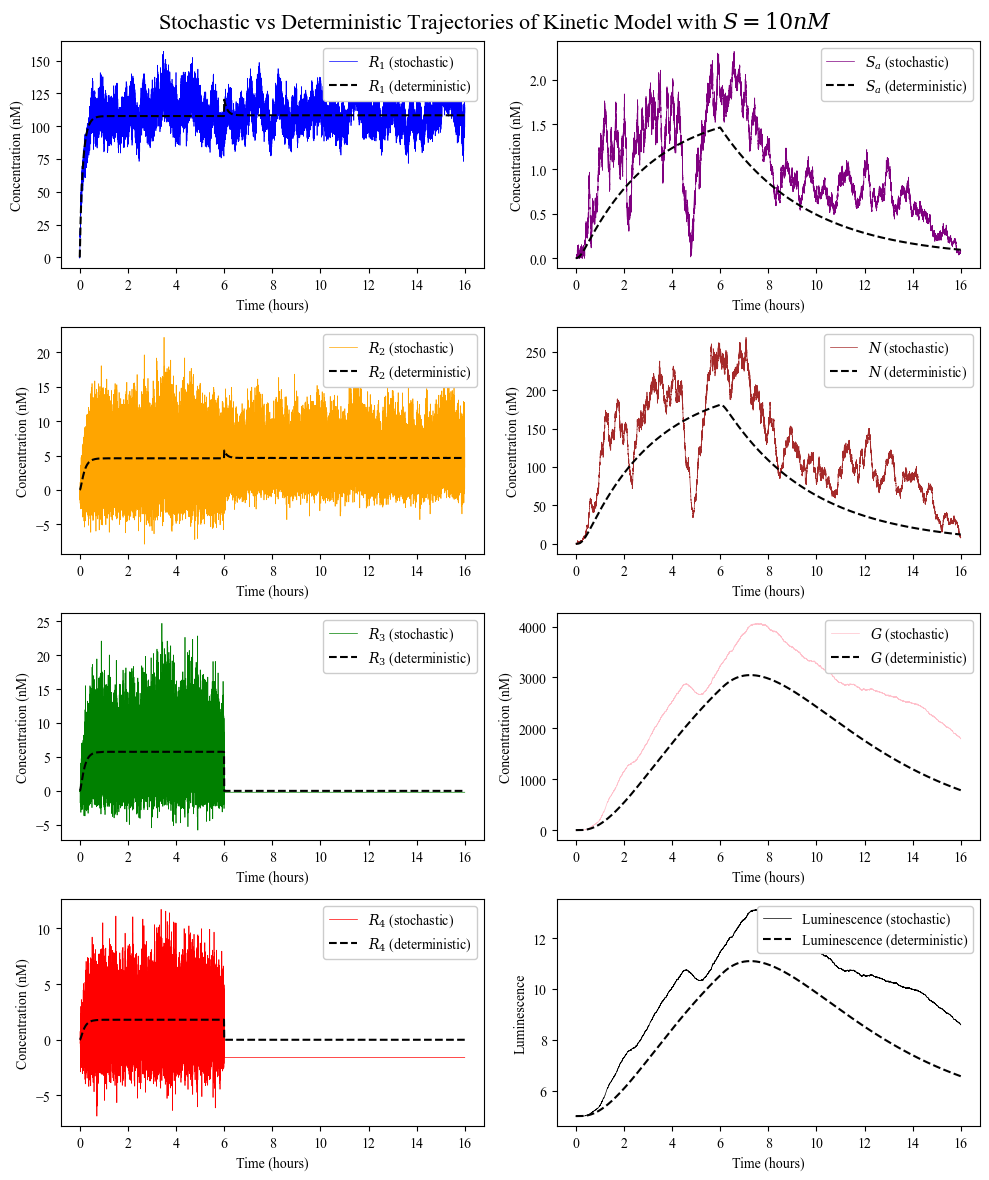

In [384]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

labels = [r'$R_1$', r'$R_2$', r'$R_3$', r'$R_4$', r'$S_a$', r'$N$', r'$G$']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'pink']
plot_variables = [0, 3, 5]

fig, axes = plt.subplots(4, 2, figsize=(10,12), dpi=100, layout='tight')

for n in range(7):
    i = n % 4
    j = int(np.floor(n/4))
    axes[i,j].plot(t_stochastic, x_stochastic[n,:], label=labels[n] + ' (stochastic)', color=colors[n], linewidth=0.5)
    axes[i,j].plot(t_deterministic, x_deterministic[n,:], label=labels[n] + ' (deterministic)', color='black', linestyle='dashed')
    axes[i,j].legend(loc='upper right', framealpha=1)
    axes[i,j].set_xlabel('Time (hours)')
    axes[i,j].set_ylabel('Concentration (nM)')

axes[3,1].plot(t_stochastic, gfp_to_luminescence(x_stochastic[6, :]), label='Luminescence (stochastic)', color='black', linewidth=0.5)
axes[3,1].plot(t_deterministic, gfp_to_luminescence(x_deterministic[6, :]), label='Luminescence (deterministic)', color='black', linestyle='dashed')
axes[3,1].legend(loc='upper right', framealpha=1)
axes[3,1].set_xlabel('Time (hours)')
axes[3,1].set_ylabel('Luminescence')

fig.suptitle(r'Stochastic vs Deterministic Trajectories of Kinetic Model with $S = 10 nM$', fontsize=16)

plt.savefig('Figures/stochastic_vs_deterministic_trajectories_no_zero_BC.png', dpi=300)

In [ ]:
odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

init_cond = [0, 0, 0, 0, 0, 0, 0]
tmax = 200
dt = 0.0001
t_values = np.arange(0, tmax, dt)
num_trajectories = 10 # number of stochastic trajectories to simulate

s_fun = lambda t: 10

trajectories = []

for i in range(num_trajectories):
    _, x_stochastic = euler_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars)
    trajectories.append(x_stochastic)
    print(f'Simulation {i+1} of {num_trajectories} complete.')

[==================================================] 100% Simulation complete.                    Simulation 1 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 2 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 3 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 4 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 5 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 6 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 7 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 8 

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6,3), dpi=100)

[ax.plot(t_values, gfp_to_luminescence(trajectories[i][6,:]), linewidth=0.5) for i in range(num_trajectories)]

ax.set_xlabel('Time')
ax.set_ylabel('Luminescence')
ax.set_title(r'Stochastic trajectories of luminescence with $S = 10 nM$')

plt.savefig('Figures/sample_stochastic_trajectories_10nM_signal.png', dpi=300)

<BarContainer object of 50 artists>

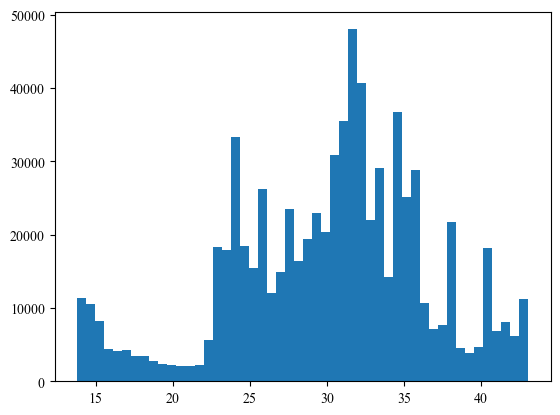

In [257]:
tmin = 25
tmax = 100

tail_indices = np.where((t_values >= tmin) & (t_values <= tmax))[0]
tail_times = t_values[tail_indices]
trajectories = np.array(trajectories)
trajectory_tails = trajectories[:,:,tail_indices]

hist, bin_edges = np.histogram(gfp_to_luminescence(trajectory_tails[0,6,:]), bins=50)
plt.bar(bin_edges[:-1], hist, width=np.diff(bin_edges), align='edge')

### Drift-Implicit Euler Method

In [ ]:
from scipy.optimize import root

'''Implementation of an implicit solver for greater stability with larger time steps.'''
def drift_implicit_euler_method(tmax, dt, x0, signal_fun, pars, G_matrix_update_fun=update_G_matrix, get_dw_fun=None):
    t_values = np.arange(0, tmax, dt)
    x_values = np.zeros((len(t_values), len(x0)))
    x_values[0] = x0

    mu = lambda t, x: kinetic_ODEs(t, x, signal_fun, pars)
    G_constants = get_constant_G_matrix(pars)
    G = G_matrix_update_fun(0, x0, np.zeros((7,19)), G_constants, signal_fun, pars)

    for i in range(1, len(t_values)):
        t = t_values[i-1]
        x = x_values[i-1]
        G = G_matrix_update_fun(t, x, G, G_constants, signal_fun, pars)
        x_values[i] = drift_implicit_euler_step(t, dt, x, mu, G, pars, get_dw_fun)
        #x_values[i] = np.where(x_values[i] < 0, 0, x_values[i]) # absorbing boundary condition
        #x_values[i,4] = min(x_values[i,4], pars['S_t']) # cap S_a at S_t
        if i % (len(t_values) // 100) == 0: print_progress(i, len(t_values), 'Simulating stochastic trajectory...')

    print_progress(len(t_values), len(t_values), 'Simulation complete.' + ' '*20)
    #print('\rSimulation complete.', end=80*' ')
    sys.stdout.flush()
    
    return t_values, np.transpose(x_values)

def drift_implicit_euler_step(t, dt, x, mu, G, pars, get_dw_fun=None):
    # Calculate noise
    if get_dw_fun is not None: dw = get_dw_fun(x, dt)
    else: dw = np.random.normal(size=19) * np.sqrt(dt)
    noise = G @ dw

    # Solve for the new state using the implicit Euler method
    x_guess = x + mu(t, x)*dt + noise # initial guess using explicit Euler
    xnew = root(lambda x_new: x_new - x - mu(t + dt, x_new)*dt - noise, x_guess).x
    xnew[4] = max(0, min(xnew[4], pars['S_t'])) # keep S_a between 0 and S_t
    
    return xnew

### Testing the Implicit Euler Method with Las Subsystem Stochasticity Removed

[==================================================] 100% Simulation complete.                    

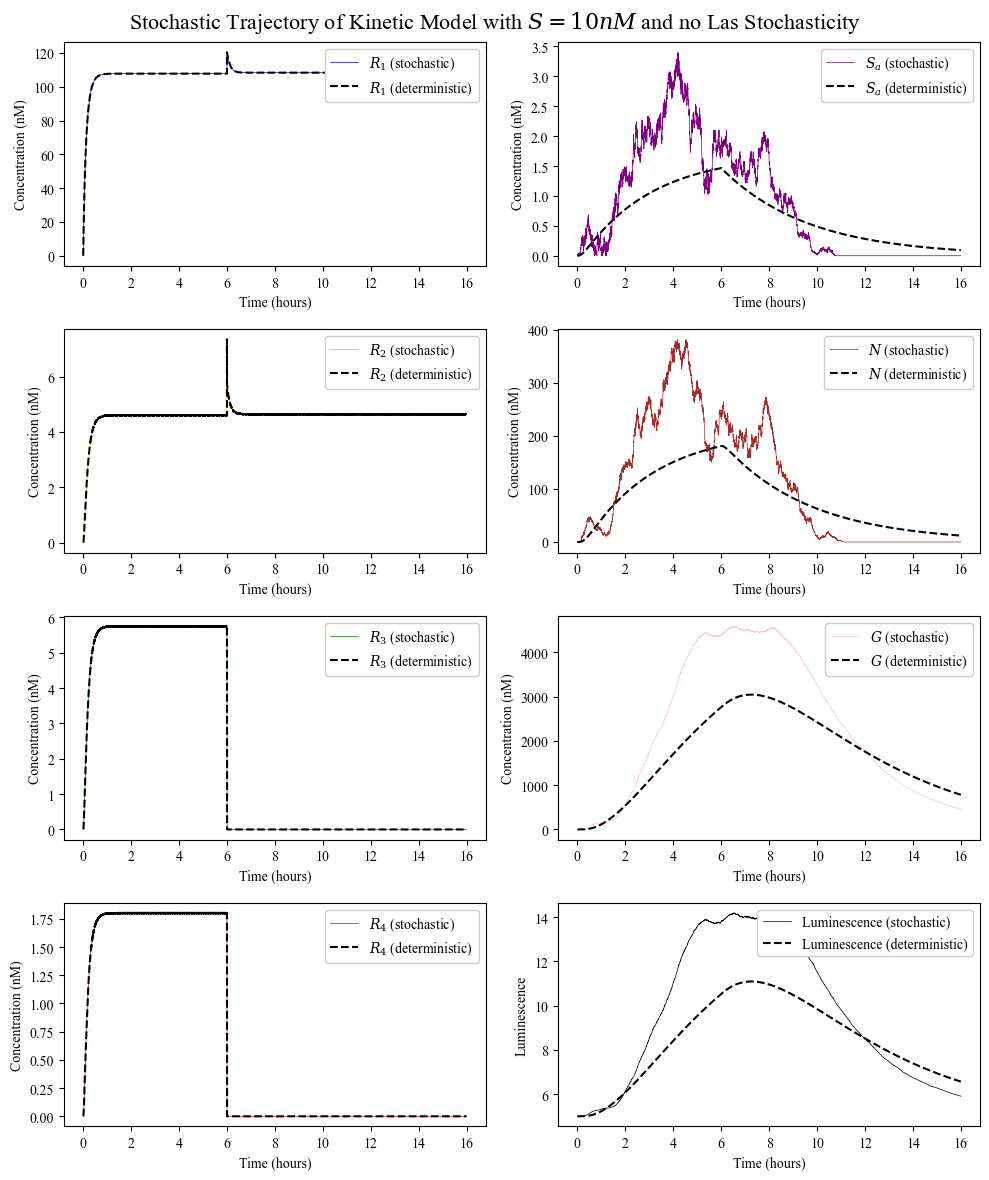

In [ ]:
odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

init_cond = [0, 0, 0, 0, 0, 0, 0]
tmax = 16
dt = 0.001

def s_fun(t):
    return 10 if t <= 6 else 0

#sys.stdout.write('Solving ODE...')
#sol = solve_ivp(odefun, [0, tmax], init_cond)
#t_deterministic, x_deterministic = sol.t, sol.y
#sys.stdout.write('\rODE solution complete.' + ' '*20 + '\n')
#sys.stdout.flush()

t_stochastic_las_removed, x_stochastic_las_removed = drift_implicit_euler_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars, G_matrix_update_fun=update_G_matrix_las_removed)

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

labels = [r'$R_1$', r'$R_2$', r'$R_3$', r'$R_4$', r'$S_a$', r'$N$', r'$G$']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'pink']

fig, axes = plt.subplots(4, 2, figsize=(10,12), dpi=100, layout='tight')
legend_loc = 'upper right'

for n in range(7):
    i = n % 4
    j = int(np.floor(n/4))
    axes[i,j].plot(t_stochastic_las_removed, x_stochastic_las_removed[n,:], label=labels[n] + ' (stochastic)', color=colors[n], linewidth=0.5)
    axes[i,j].plot(t_deterministic, x_deterministic[n,:], label=labels[n] + ' (deterministic)', color='black', linestyle='dashed')
    axes[i,j].legend(loc=legend_loc, framealpha=1)
    axes[i,j].set_xlabel('Time (hours)')
    axes[i,j].set_ylabel('Concentration (nM)')

axes[3,1].plot(t_stochastic_las_removed, gfp_to_luminescence(x_stochastic_las_removed[6, :]), label='Luminescence (stochastic)', color='black', linewidth=0.5)
axes[3,1].plot(t_deterministic, gfp_to_luminescence(x_deterministic[6, :]), label='Luminescence (deterministic)', color='black', linestyle='dashed')
axes[3,1].legend(loc=legend_loc, framealpha=1)
axes[3,1].set_xlabel('Time (hours)')
axes[3,1].set_ylabel('Luminescence')

fig.suptitle(r'Stochastic Trajectory of Kinetic Model with $S = 10 nM$ and no Las Stochasticity', fontsize=16)

plt.savefig('Figures/stochastic_trajectory_las_removed.png', dpi=300)

In [10]:
odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

init_cond = [0, 0, 0, 0, 0, 0, 0]
tmax = 200
dt = 0.01
t_values = np.arange(0, tmax, dt)
num_trajectories = 10 # number of stochastic trajectories to simulate

s_fun = lambda t: 10

trajectories = []

for i in range(num_trajectories):
    _, x_stochastic = drift_implicit_euler_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars, get_dw_fun=get_dw)
    trajectories.append(x_stochastic)
    print(f'Simulation {i+1} of {num_trajectories} complete.')

[==================================================] 100% Simulation complete.                    Simulation 1 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 2 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 3 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 4 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 5 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 6 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 7 of 10 complete.
[==================================================] 100% Simulation complete.                    Simulation 8 

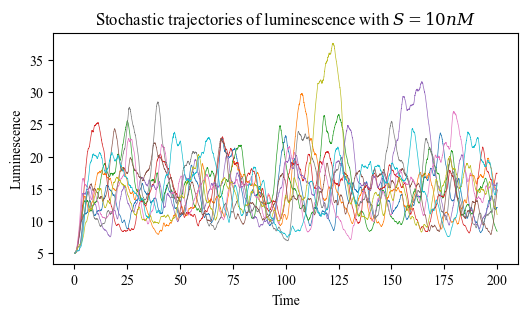

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(6,3), dpi=100)

[ax.plot(t_values, gfp_to_luminescence(trajectories[i][6,:]), linewidth=0.5) for i in range(num_trajectories)]

ax.set_xlabel('Time')
ax.set_ylabel('Luminescence')
ax.set_title(r'Stochastic trajectories of luminescence with $S = 10 nM$')

plt.savefig('Figures/sample_stochastic_trajectories_10nM_signal.png', dpi=300)

<BarContainer object of 50 artists>

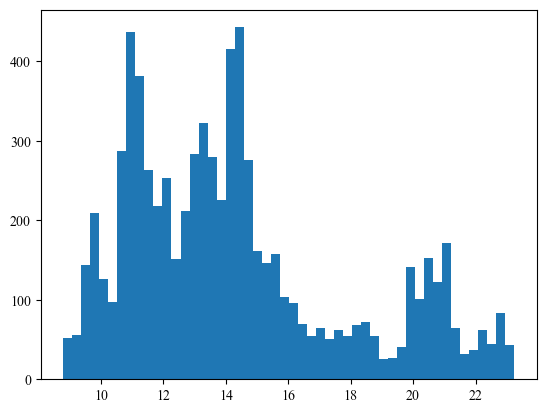

In [12]:
tmin = 25
tmax = 100

tail_indices = np.where((t_values >= tmin) & (t_values <= tmax))[0]
tail_times = t_values[tail_indices]
trajectories = np.array(trajectories)
trajectory_tails = trajectories[:,:,tail_indices]

hist, bin_edges = np.histogram(gfp_to_luminescence(trajectory_tails[0,6,:]), bins=50)
plt.bar(bin_edges[:-1], hist, width=np.diff(bin_edges), align='edge')

Alternative approach for the zero BC: if $x_i < 0$, check $dw(t)$ to make sure that the noise being applied to $x_i$ is non-negative. When $d\vec{w}$ is generated, see if the $i$th component, $dw_i$, multiplied by the corresponding entry in $G$, will result in $x_i$ decreasing. If so, set that noise component $dw_i$ equal to zero. This prevents the artificial introduction of extra molecules.

In [5]:
def get_dw(x, dt):
    dw = np.random.normal(size=19) * np.sqrt(dt)
    if x[0] < 0: # if R_1 is negative, set all noise terms involving R_1 to be greater than zero
        dw[0] = max(dw[0], 0) # if R_1 is negative, set g_1 noise term to be greater than zero
        dw[1] = min(dw[1], 0) # if R_1 is negative, set g_2 noise term to be greater than zero
        dw[2] = min(dw[2], 0) # if R_1 is negative, set g_3 noise term to be greater than zero
        dw[3] = max(dw[3], 0) # if R_1 is negative, set g_4 noise term to be greater than zero
    if x[1] < 0: # if R_2 is negative, set all noise terms involving R_2 to be greater than zero
        dw[2] = max(dw[2], 0) # if R_2 is negative, set g_3 noise term to be greater than zero
        dw[3] = min(dw[3], 0) # if R_2 is negative, set g_4 noise term to be greater than zero
        dw[4] = min(dw[4], 0) # if R_2 is negative, set g_5 noise term to be greater than zero
        dw[5] = min(dw[5], 0) # if R_2 is negative, set g_6 noise term to be greater than zero
        dw[6] = max(dw[6], 0) # if R_2 is negative, set g_7 noise term to be greater than zero
    if x[2] < 0: # if R_3 is negative, set all noise terms involving R_3 to be greater than zero
        dw[5] = max(dw[5], 0) # if R_3 is negative, set g_6 noise term to be greater than zero
        dw[6] = min(dw[6], 0) # if R_3 is negative, set g_7 noise term to be greater than zero
        dw[7] = min(dw[7], 0) # if R_3 is negative, set g_8 noise term to be greater than zero
        dw[8] = min(dw[8], 0) # if R_3 is negative, set g_9 noise term to be greater than zero
        dw[9] = max(dw[9], 0) # if R_3 is negative, set g_10 noise term to be greater than zero
    if x[3] < 0: # if R_4 is negative, set all noise terms involving R_4 to be greater than zero
        dw[8] = max(dw[8], 0) # if R_4 is negative, set g_9 noise term to be greater than zero
        dw[9] = min(dw[9], 0) # if R_4 is negative, set g_10 noise term to be greater than zero
        dw[10] = min(dw[10], 0) # if R_4 is negative, set g_11 noise term to be greater than zero

    return dw

[==================================================] 100% Simulation complete.                    

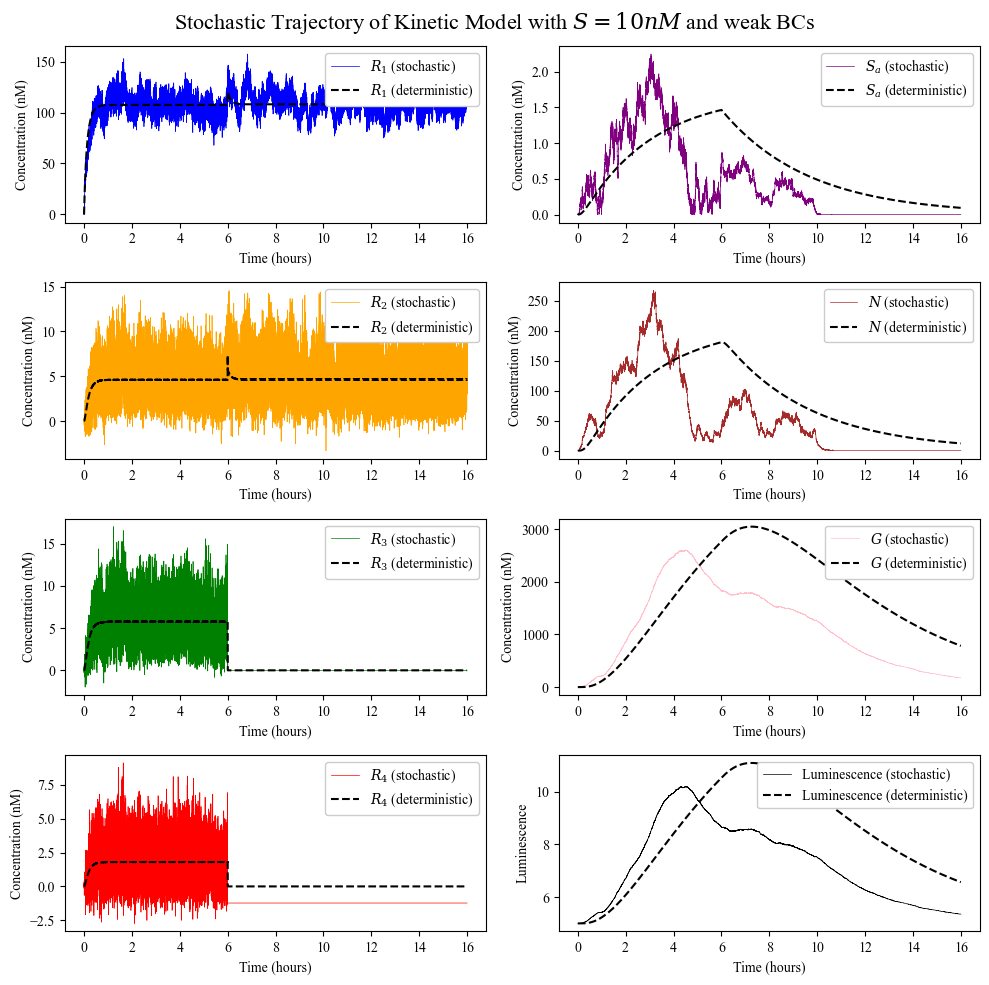

In [24]:
from scipy.integrate import solve_ivp

odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

init_cond = [0, 0, 0, 0, 0, 0, 0]
tmax = 16
dt = 0.0001

def s_fun(t):
    return 10 if t <= 6 else 0

#sys.stdout.write('Solving ODE...')
#sol = solve_ivp(odefun, [0, tmax], init_cond)
#t_deterministic, x_deterministic = sol.t, sol.y
#sys.stdout.write('\rODE solution complete.' + ' '*20 + '\n')
#sys.stdout.flush()

t_stochastic_weak_BCs, x_stochastic_weak_BCs = drift_implicit_euler_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars, G_matrix_update_fun=update_G_matrix, get_dw_fun=get_dw)

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

labels = [r'$R_1$', r'$R_2$', r'$R_3$', r'$R_4$', r'$S_a$', r'$N$', r'$G$']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'pink']

fig, axes = plt.subplots(4, 2, figsize=(10,10), dpi=100, layout='tight')
legend_loc = 'upper right'

for n in range(7):
    i = n % 4
    j = int(np.floor(n/4))
    axes[i,j].plot(t_stochastic_weak_BCs, x_stochastic_weak_BCs[n,:], label=labels[n] + ' (stochastic)', color=colors[n], linewidth=0.5)
    axes[i,j].plot(t_deterministic, x_deterministic[n,:], label=labels[n] + ' (deterministic)', color='black', linestyle='dashed')
    axes[i,j].legend(loc=legend_loc, framealpha=1)
    axes[i,j].set_xlabel('Time (hours)')
    axes[i,j].set_ylabel('Concentration (nM)')

axes[3,1].plot(t_stochastic_weak_BCs, gfp_to_luminescence(x_stochastic_weak_BCs[6, :]), label='Luminescence (stochastic)', color='black', linewidth=0.5)
axes[3,1].plot(t_deterministic, gfp_to_luminescence(x_deterministic[6, :]), label='Luminescence (deterministic)', color='black', linestyle='dashed')
axes[3,1].legend(loc=legend_loc, framealpha=1)
axes[3,1].set_xlabel('Time (hours)')
axes[3,1].set_ylabel('Luminescence')

fig.suptitle(r'Stochastic Trajectory of Kinetic Model with $S = 10 nM$ and weak BCs', fontsize=16)

plt.savefig('Figures/stochastic_trajectory_weak_BCs.png', dpi=300)

[==================================================] 100% Simulation complete.                    

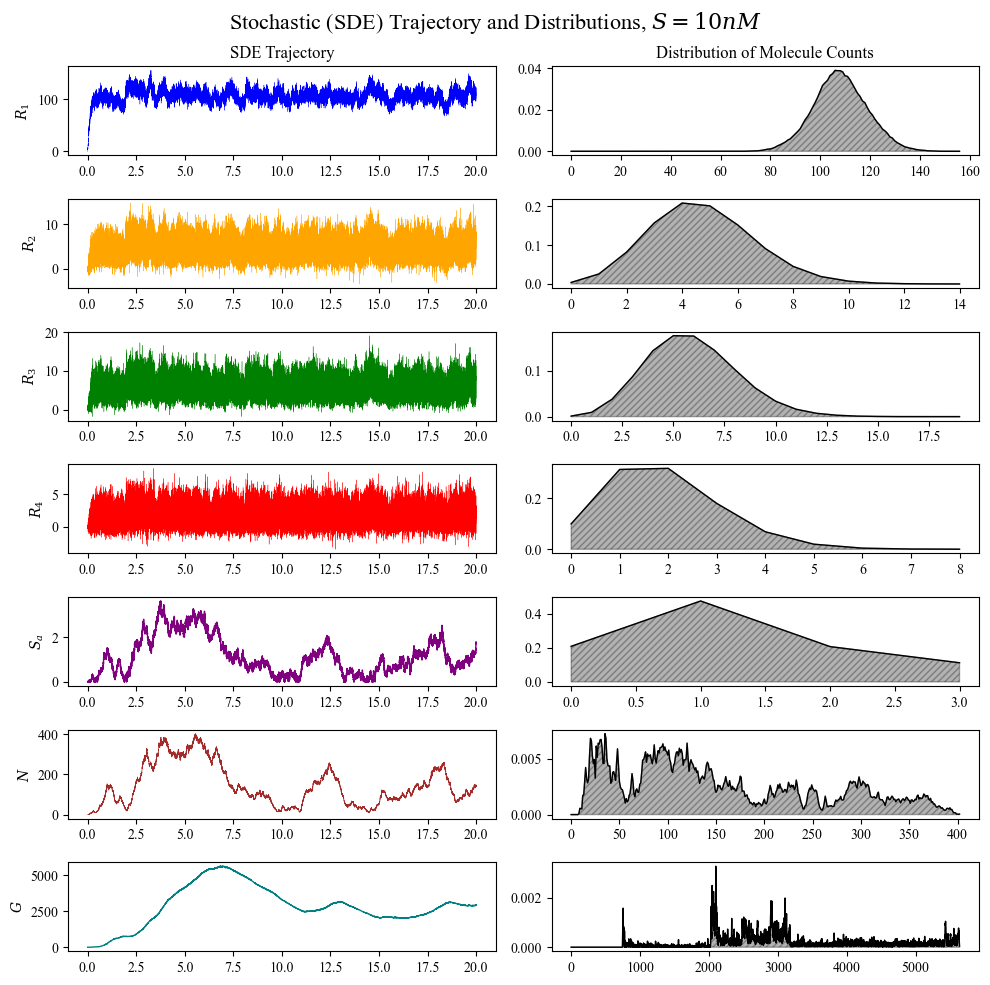

In [31]:
init_cond = [0, 0, 0, 0, 0, 0, 0]
tmax = 20
dt = 0.0001
s_fun = lambda t: 10 if t <= 20 else 0

t_2, x_2 = drift_implicit_euler_method(tmax=tmax, dt=dt, x0=init_cond, signal_fun=s_fun, pars=pars, G_matrix_update_fun=update_G_matrix, get_dw_fun=get_dw)

labels = [r'$R_1$', r'$R_2$', r'$R_3$', r'$R_4$', r'$S_a$', r'$N$', r'$G$', r'Luminescence']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'teal', 'black']
plot_linewidths = [0.25, 0.25, 0.25, 0.25, 1, 0.5, 1, 1]

test_indices = np.where((t_2 >= 2) & (t_2 <= tmax))[0]

test_values = x_2[:, test_indices]

max_values = np.max(test_values, axis=1).astype(int)

bins = [np.arange(-0.5, max_val + 1.5, 1) for max_val in max_values] # bins for histogram, from -0.5 to max+0.5 with width 1

histograms = []
bin_edges_list = []

for n in range(7):
    hist, bin_edges = np.histogram(test_values[n,:], bins=bins[n], density=True)
    histograms.append(hist)
    bin_edges_list.append(bin_edges)

fig, axes = plt.subplots(7, 2, figsize=(10,10), dpi=100, layout='tight')

for n in range(7):
    axes[n,0].plot(t_2, x_2[n,:], color=colors[n], linewidth=plot_linewidths[n])
    axes[n,1].plot(bin_edges_list[n][:-1] + 0.5, histograms[n], color='black', linestyle='-', linewidth=1)
    axes[n,1].fill_between(bin_edges_list[n][:-1] + 0.5, histograms[n], alpha=0.3, color='black', hatch='/////', edgecolor='black')
    axes[n,0].set_ylabel(labels[n])

axes[0,0].set_title('SDE Trajectory')
axes[0,1].set_title('Distribution of Molecule Counts')

fig.suptitle(r'Stochastic (SDE) Trajectory and Distributions, $S = 10 nM$', fontsize=16)
plt.savefig('Figures/SDE_trajectory_and_distributions.png', dpi=300, bbox_inches='tight')